```bash 
sbatch run_spatiallieden_ratio.py
```

In [1]:
# mamba activate scib-metrics
import numpy as np
import scanpy as sc
import igraph as ig
import pandas as pd
import os
from scipy.sparse.csgraph import connected_components
from scib.metrics import isolated_labels_asw, graph_connectivity

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib as mpl

from tqdm import tqdm
import pickle

In [2]:
# -----------------------------
# helper function
# -----------------------------
def add_cluster_from_pickle(andata, pkl_file, new_col, match_col="cell_id"):
    """
    Add clustering results from a pickle dictionary to andata.obs.

    The pickle file should contain:
        key   = original obs name
        value = cluster label
    """

    with open(pkl_file, "rb") as f:
        cluster_dict = pickle.load(f)

    # make sure dictionary keys are strings
    cluster_dict = {str(k): str(v) for k, v in cluster_dict.items()}

    # map cluster labels into AnnData
    andata.obs[new_col] = andata.obs[match_col].map(cluster_dict)

    # report mapping quality
    n_total = andata.n_obs
    n_missing = andata.obs[new_col].isna().sum()

    print(f"{new_col}")
    print(f"  total cells:   {n_total}")
    print(f"  matched cells: {n_total - n_missing}")
    print(f"  missing cells: {n_missing}")

    # convert to category for plotting
    andata.obs[new_col] = andata.obs[new_col].astype("category")

    return andata


In [5]:
pathout = '/data/HiTIF/data/spatialomics/neuroblastoma/data/andata_orig'
pathdict = '/data/HiTIF/data/spatialomics/neuroblastoma/data/misc/res_07_ratio1p5'

pathout = "/data/HiTIF/data/spatialomics/neuroblastoma/data/andata_orig"


andata = sc.read_h5ad(os.path.join(pathout, "adata_nb_processed.h5ad"))


seed = 1948
np.random.seed(seed)
andata.obsp['connectivities'] = andata.obsp['30neig_connectivities']
andata.obsp['distances'] = andata.obsp['30neig_distances']

In [6]:
pkl_dir = '/data/HiTIF/data/spatialomics/neuroblastoma/data/misc/res_07_ratio1p5'

andata = add_cluster_from_pickle(
    andata,
    os.path.join(pkl_dir, "stlieden_ratio1p5_r3.pkl"),
    "stlieden_ratio1p5_r3",match_col='cell_id'
)

andata = add_cluster_from_pickle(
    andata,
    os.path.join(pkl_dir, "stlieden_ratio1p5_r8.pkl"),
    "stlieden_ratio1p5_r8",match_col='cell_id'
)

andata = add_cluster_from_pickle(
    andata,
    os.path.join(pkl_dir, "stlieden_ratio1p5_r13.pkl"),
    "stlieden_ratio1p5_r13",match_col='cell_id'
)

andata = add_cluster_from_pickle(
    andata,
    os.path.join(pkl_dir, "stlieden_ratio1p5_r18.pkl"),
    "stlieden_ratio1p5_r18",match_col='cell_id'
)

stlieden_ratio1p5_r3
  total cells:   669261
  matched cells: 669261
  missing cells: 0
stlieden_ratio1p5_r8
  total cells:   669261
  matched cells: 669261
  missing cells: 0
stlieden_ratio1p5_r13
  total cells:   669261
  matched cells: 669261
  missing cells: 0
stlieden_ratio1p5_r18
  total cells:   669261
  matched cells: 669261
  missing cells: 0


In [7]:
neighbors_key = "30neig"  # or "10neig"
connectivities_key = f"{neighbors_key}_connectivities"
distances_key = f"{neighbors_key}_distances"

andata.obsp["connectivities"] = andata.obsp[connectivities_key].copy()
andata.obsp["distances"] = andata.obsp[distances_key].copy()
andata.uns["neighbors"] = andata.uns[neighbors_key]

expression_connectivities = andata.obsp[connectivities_key]

g = sc._utils.get_igraph_from_adjacency(
    expression_connectivities,
    directed=False,
)

In [8]:
spatialleiden_cols = {
    3.0: "stlieden_ratio1p5_r3",
    8.0: "stlieden_ratio1p5_r8",
    13.0: "stlieden_ratio1p5_r13",
    18.0: "stlieden_ratio1p5_r18",
}

missing_cols = [col for col in spatialleiden_cols.values() if col not in andata.obs]
if missing_cols:
    raise KeyError(f"Missing spatial Leiden columns in andata.obs: {missing_cols}")

In [9]:
def per_label_connectivity(adata, label_key, connectivities):
    rows = []
    labels = adata.obs[label_key].astype("category")

    for label in labels.cat.categories:
        cell_mask = labels == label
        cell_index = np.flatnonzero(cell_mask.to_numpy())

        subgraph = connectivities[cell_index, :][:, cell_index]

        n_components, component_labels = connected_components(
            subgraph,
            directed=False,
            connection="weak",
        )

        component_sizes = np.bincount(component_labels)
        largest_component_fraction = component_sizes.max() / cell_index.size

        rows.append(
            dict(
                label_key=label_key,
                label=str(label),
                n_cells=cell_index.size,
                n_components=n_components,
                largest_component_fraction=largest_component_fraction,
            )
        )

    return pd.DataFrame(rows)

In [10]:
scores = []
connectivity_details = []

n_graph_components, graph_components = connected_components(
    expression_connectivities,
    directed=False,
    connection="weak",
)

graph_component_sizes = pd.Series(graph_components).value_counts().sort_values(ascending=False)

print(f"Whole {neighbors_key} expression graph components: {n_graph_components}")
display(graph_component_sizes.head().rename("n_cells").to_frame())

for spatial_ratio, label_key in tqdm(spatialleiden_cols.items()):
    valid = andata.obs[label_key].notna().to_numpy()

    if valid.sum() != andata.n_obs:
        print(
            f"{label_key}: using {valid.sum()} / {andata.n_obs} cells "
            "because some labels are missing."
        )

    adata_valid = andata[valid].copy()
    valid_connectivities = expression_connectivities[valid, :][:, valid]

    graph = sc._utils.get_igraph_from_adjacency(
        valid_connectivities,
        directed=False,
    )

    labels = pd.Categorical(adata_valid.obs[label_key]).codes.tolist()
    n_clusters = adata_valid.obs[label_key].nunique()

    modularity = graph.modularity(labels, weights=graph.es["weight"])

    detail = per_label_connectivity(
        adata_valid,
        label_key,
        valid_connectivities,
    )
    detail["spatial_ratio"] = spatial_ratio
    connectivity_details.append(detail)

    scores.append(
        dict(
            spatial_ratio=spatial_ratio,
            modularity=modularity,
            n_clusters=n_clusters,
            disconnected_labels=(detail["n_components"] > 1).sum(),
            min_largest_component_fraction=detail["largest_component_fraction"].min(),
            label_key=label_key,
            n_cells=valid.sum(),
        )
    )

connectivity_details = pd.concat(connectivity_details, ignore_index=True)
spatial_ratio_df = pd.DataFrame(scores).set_index("spatial_ratio").sort_index()

spatial_ratio_df

Whole 30neig expression graph components: 1


,n_cells
0,669261


100%|██████████| 4/4 [01:29<00:00, 22.35s/it]


,modularity,n_clusters,disconnected_labels,min_largest_component_fraction,label_key,n_cells
spatial_ratio,,,,,,
3.0,0.826419,15,0,1.000000,stlieden_ratio1p5_r3,669261
8.0,0.830140,15,0,1.000000,stlieden_ratio1p5_r8,669261
13.0,0.819272,13,7,0.999675,stlieden_ratio1p5_r13,669261
18.0,0.721648,10,10,0.991496,stlieden_ratio1p5_r18,669261


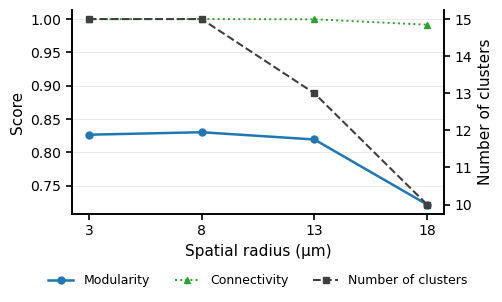

In [12]:

fig, ax1 = plt.subplots(figsize=(4.8, 3.4))

ax1.plot(
    spatial_ratio_df.index,
    spatial_ratio_df["modularity"],
    marker="o",
    markersize=5,
    linewidth=1.8,
    color="#1f77b4",
    label="Modularity",
)

ax1.plot(
    spatial_ratio_df.index,
    spatial_ratio_df["min_largest_component_fraction"],
    marker="^",
    markersize=4.5,
    linewidth=1.4,
    linestyle=":",
    color="#2ca02c",
    label="Connectivity",
)

ax1.set_xlabel("Spatial radius (µm)", fontsize=11)
ax1.set_ylabel("Score", fontsize=11)
ax1.set_xticks(spatial_ratio_df.index)
ax1.tick_params(axis="both", labelsize=10, width=1.2, length=4)

ax2 = ax1.twinx()
ax2.plot(
    spatial_ratio_df.index,
    spatial_ratio_df["n_clusters"],
    marker="s",
    markersize=4.5,
    linewidth=1.5,
    linestyle="--",
    color="0.25",
    label="Number of clusters",
)

ax2.set_ylabel("Number of clusters", fontsize=11)
ax2.tick_params(axis="y", labelsize=10, width=1.2, length=4)
from matplotlib.ticker import MaxNLocator
ax2.yaxis.set_major_locator(MaxNLocator(integer=True))


for ax in [ax1, ax2]:
    ax.spines["top"].set_visible(False)
    ax.spines["bottom"].set_linewidth(1.2)
    ax.spines["left"].set_linewidth(1.2)
    ax.spines["right"].set_linewidth(1.2)

ax1.grid(axis="y", linewidth=0.6, alpha=0.3)
ax1.set_axisbelow(True)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    frameon=False,
    fontsize=9,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.24),
    ncol=3,
)

plt.subplots_adjust(bottom=0.28)
plt.show()